<h1 align="center">Práctica 6. MF-sets</h1>
<h3 style="display:block; margin-top:5px;" align="center">Estructuras de datos</h3>
<h3 style="display:block; margin-top:5px;" align="center">2026-2027</h3>    
<h3 style="display:block; margin-top:5px;" align="center">Universitat Politècnica de València</h3>
<br>

**Pon/poned aquí tú/vuestros nombre(s):**
- (sustituir por el nombre)
- (sustituir por el nombre o borrar si se realiza individualmente)

## Índice
- ### [Introducción y objetivos](#intro)
- ### [Actividad 1: Contar componentes 4-conectadas y el nº pixels.](#act1)
- ### [Actividad 2: Obtener las *bounding boxes*](#act2)
- ### [Actividad 3: (ampliación opcional) Clasificar figuras](#act3)

<a id='intro'></a>
## Introducción: Objetivos de la práctica

El objetivo de esta práctica es utilizar la estructura de datos [MF-sets](https://en.wikipedia.org/wiki/Disjoint-set_data_structure) para contabilizar el número de manchas de tinta [4-conectadas](https://en.wikipedia.org/wiki/Pixel_connectivity#4-connected) en una imagen (en blanco y negro, aunque se podría trabajar con escalas de gris o color) y algunas de sus características (nº de píxels y la caja que las engloba o [bounding box](https://en.wikipedia.org/wiki/Minimum_bounding_rectangle)). Esta tarea está muy relacionada con un problema llamado [Connected-component labeling (enlace a wikipedia)](https://en.wikipedia.org/wiki/Connected-component_labeling).

### Etiquetado de componentes conexas (connected-component labeling)

Este problema, muy útil en el campo de [Computer vision](https://en.wikipedia.org/wiki/Computer_vision), consiste en etiquetar los pixels de una imagen de manera que todos los pixels de cada componente 4-conectada de la imagen compartan una misma etiqueta (y que cada componente tenga una etiqueta diferente).

En la figura siguiente puedes ver la diferencia entre 8-conectado (izquierda) y 4-conectado (derecha):

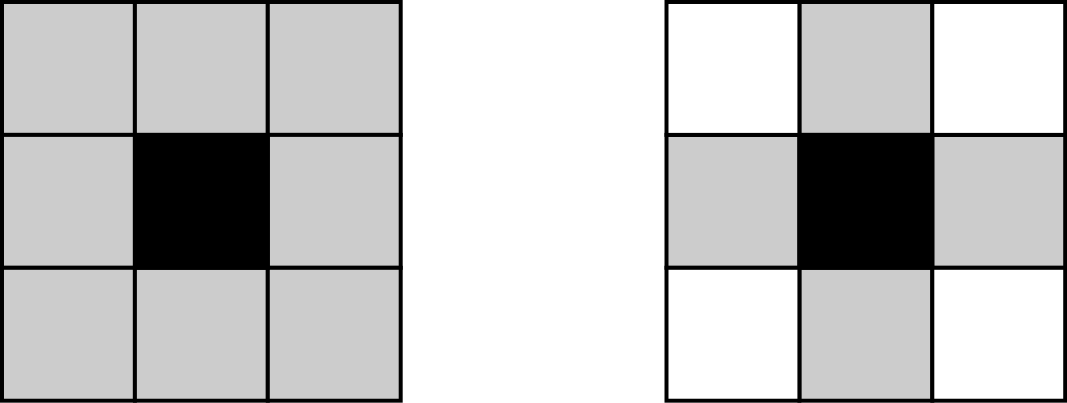

> **Nota:** En esta práctica solamente vamos a trabajar con componentes 4-conectadas, pero no sería difícil adaptarlo al caso de imágenes 8-conectadas, bastaría con considerar también los vecinos en diagonal.

La siguiente figura ilustra el *Connected-component labeling*:

- A la izquierda tenemos la imagen original en blanco y negro de la que queremos identificar sus componentes 4-conectadas y asociarles un identificador único.
- A su derecha vemos la misma imagen donde, a cada pixel, se le ha asociado una etiqueta (1,2,4,5,7) de modo que cada componente 4-conectada tiene todos sus pixels con la misma etiqueta.

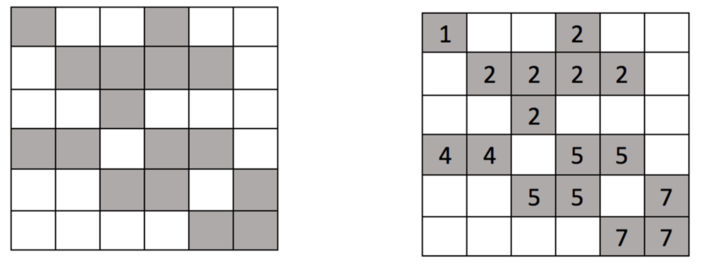

Existen varias formas de resolver este problema. Se podrían utilizar [algoritmos de recorridos de grafos](https://en.wikipedia.org/wiki/Graph_traversal#Graph_traversal_algorithms) como el [BFS](https://en.wikipedia.org/wiki/Breadth-first_search) o el [DFS](https://en.wikipedia.org/wiki/Depth-first_search), pero en esta práctica vamos a utilizar MF-sets y, más concretamente, el algoritmo de [Hoshen-Kopelman](https://en.wikipedia.org/wiki/Hoshen%E2%80%93Kopelman_algorithm)

La idea del algoritmo de Hoshen-Kopelman consiste en recorrer toda la imagen de arriba a abajo y, para cada fila, de izquierda a derecha. Nos detenemos únicamente en los pixels de tinta, que llamaremos el pixel *actual* en la descripción que sigue. Dado el pixel actual, observamos a dos de sus vecinos:

- El pixel que está **arriba** del actual.
- El pixel que está a la **izquierda** del actual.

> **Cuestión:** ¿Por qué es suficiente ver esos 2 pixels y no se comprueba el que tiene debajo ni el que tiene a su derecha?

Entonces pueden suceder estos tres casos:

1. **Ninguno de los pixels vecinos tiene tinta:** En ese caso asociamos al pixel actual un identificador/etiqueta nuevo/a. Para ello podemos tener un contador con el que ir generando  identificadores (devolvemos ese valor y luego incrementamos el contador).
2. **Solamente uno de los vecinos tiene tinta, el otro no:** Copiamos el identificador/etiqueta del vecino al pixel actual.
3. **Los dos vecinos tienen tinta:** en ese caso nos copiamos uno de los dos identificadores pero, además, queremos que ambos identificadores se consideren a partir de ahora como formando parte de la misma componente 4-conectada. Si los dos vecinos tienen tinta, asignamos al píxel actual una de las dos etiquetas. Además, si las etiquetas pertenecen a clases de equivalencia diferentes, debemos fusionar dichas clases mediante la operación `merge` del MF-set.

Veamos cómo cargar una imagen en Python y qué aspecto tendría el algoritmo que etiqueta los pixels:

## Cómo cargar y manipular imágenes con la biblioteca `PIL.Image`:

El módulo `PIL` [(ver el siguiente enlace)](https://pillow.readthedocs.io/en/stable/) permite cargar, manipular y guardar imágenes en diferentes formatos. Veamos cómo cargar una imagen, lo primero es importarlo:

In [106]:
import matplotlib.pyplot as plt
from PIL import Image

Ahora vamos a utilizar la clase `Image` de la biblioteca [PIL](https://pillow.readthedocs.io/en/3.1.x/reference/Image.html). Lo más sencillo es cargar una imagen con `Image.open`:

<class 'PIL.PngImagePlugin.PngImageFile'>
<class 'PixelAccess'>


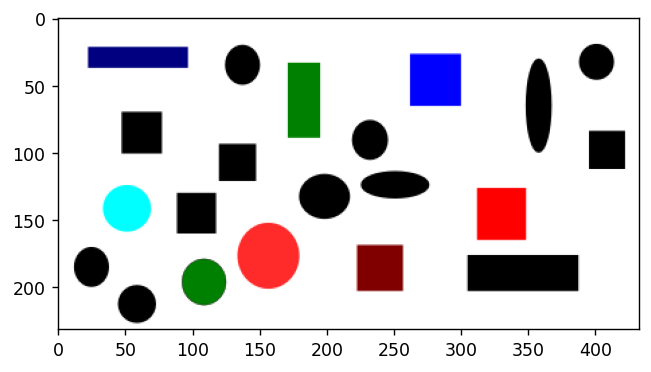

In [107]:
%matplotlib inline
img = Image.open("ejemplo_color.png")
plt.figure(dpi=125) # para que lo muestre un poco más grande
plt.imshow(img)
print(type(img))
p = img.load() # pixel access
print(type(p))

Veamos cómo se puede obtener el tamaño de la imagen:

In [108]:
width, height = img.size
print(f'imagen de talla {width} de ancho por {height} de alto')

imagen de talla 433 de ancho por 232 de alto


Podemos consultar el contenido de la imagen con el método `getpixel` o directamente con `[h,v]` aplicado a un objeto *pixel access*. El método `getpixel` recibe un sólo parámetro con una coordenada (una tupla) y devuelve un valor que depende del modo de la imagen. Para ver el modo de la imagen podemos hacer esto:

In [109]:
print(f'imagen con modo {img.mode}')

imagen con modo RGBA


Al tratarse del modo RGBA cada pixel vendrá dado por una tupla con 4 valores:

In [110]:
coordenada = (275,47)
pixel = img.getpixel(coordenada)
print(pixel) # (0, 0, 255, 255) color azul
pixel = p[150,180] # otra forma, usando p que es un pixel access de img
print(pixel) # (255, 42, 42, 255) pixel rojo del círculo rojo

(0, 0, 255, 255)
(255, 42, 42, 255)


Podemos convertir la imagen a grises así:

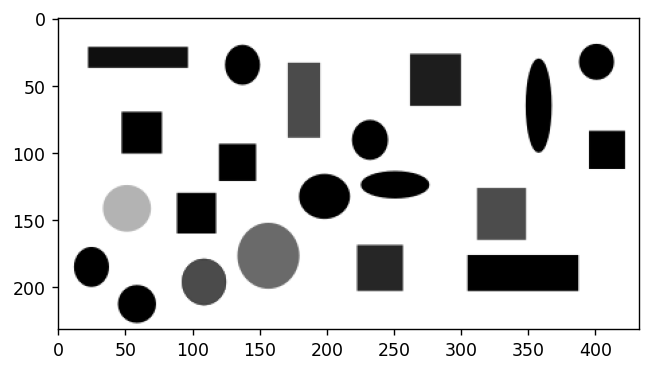

In [111]:
%matplotlib inline
gray_img = img.convert('I') # pasamos a escala de grises valores enteros
plt.figure(dpi=125) # para que lo muestre un poco más grande
plt.imshow(gray_img)

In [112]:
pixel = gray_img.getpixel(coordenada)
print(pixel) # este pixel es gris oscuro, 29 cercano al 0 que es negro
p = gray_img.load()
print(p[10,10]) # este pixel es blanco, 255 es blanco

29
255


Ahora vamos a utilizar la del ejemplo utilizado para la *connected-component labeling*:

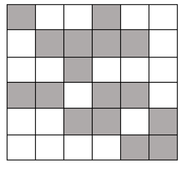

Una forma sencilla de obtener la imagen anterior sería escribirla directamente en formato PBM de tipo ASCII (ver [el siguiente enlace](https://en.wikipedia.org/wiki/Netpbm#File_formats)):

```
P1
# ejemplo 1
6 6
1 0 0 1 0 0
0 1 1 1 1 0
0 0 1 0 0 0
1 1 0 1 1 0
0 0 1 1 0 1
0 0 0 0 1 1
```

Pero aparentemente la biblioteca PIL de Python no es capaz de cargar un fichero en este formato, nos da el siguiente error:

```
raise UnidentifiedImageError(
PIL.UnidentifiedImageError: cannot identify image file 'ejemplo1.pbm'
```

Por lo que se os proporciona en poliformat la imagen anterior ya convertida a formato [PNG](https://en.wikipedia.org/wiki/Portable_Network_Graphics). Para generar esa imagen nosotros hemos utilizando la herramienta [convert](https://en.wikipedia.org/wiki/ImageMagick), es decir, con el siguiente comando:

```
convert ejemplo1.pbm ejemplo1.png
```

Junto a este notebook tienes el fichero `ejemplo1.png` y otros similares.

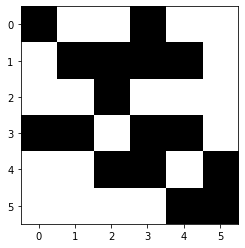

In [113]:
%matplotlib inline
img = Image.open("ejemplo1.png")
plt.imshow(img)

Observa que el siguiente código imprime básicamente la misma figura mostrando los niveles de gris (0 es negro y 255 es blanco):

In [114]:
width,height = img.size
p = img.load()
for w in range(height):
    for h in range(width):
        print(f"{p[h,w]:4}",end="")
    print()

   0 255 255   0 255 255
 255   0   0   0   0 255
 255 255   0 255 255 255
   0   0 255   0   0 255
 255 255   0   0 255   0
 255 255 255 255   0   0


<a id='act1'></a>
## Actividad 1: Contar componentes 4-conectadas y el nº pixels.

En lugar de etiquetar cada pixel de la imagen con una etiqueta única para cada componente conexa, vamos a limitarnos a **contar el número de componentes conexas 4-conectadas** que hay en la imagen y el número de pixels que tiene cada una.

La **entrada** del algoritmo será una imagen y un nivel de gris que llamaremos **umbral** (tendrá un valor por defecto). Todos los pixels que, pasados a gris, tengan un brillo menor o igual al umbral se consideran tinta, mientras que el resto de pixels se considerarán fondo.

La **salida** del algoritmo es una lista donde, para cada componente 4-conectada de la imagen, vamos a proporcionar la siguiente información:

- Nº de pixels de tinta.

Para ello has de completar la clase `CountCC` que realiza la función de MF-set utilizando un diccionario Python llamado `self._p` (similar al `self._p` de teoría) como representación del mismo. Utiliza la *representación en bosque* de MF-sets (ver teoría) donde cada árbol es una clase de equivalencia y la raíz es el representante.

La clase `CountCC`tiene los siguientes métodos:

- El constructor crea estos atributos:
    - `self.labelCount` sirve para ir generando etiquetas nuevas, debe inicializarse a 0 y se irá incrementando cuando haga falta.
    - `self._p` es un diccionario (inicialmente vacío) con el mismo nombre y función que en los MF-set vistos en teoría. Las claves son **LAS ETIQUETAS QUE NO SON REPRESENTANTE** y el valor asociado es su padre en el árbol (representación en bosque del MF-set). Si una etiqueta no es una clave de este diccionario significa que es un representante de su clase.
    - `self.numpixels` es **otro diccionario** que asocia al representante de cada clase el nº de pixels de esa componente conexa.
- El método `getNewLabel` nos devuelve una nueva etiqueta. Para ello hace uso de `self.labelCount` (le asocia ese valor y luego incrementa el atributo). La nueva etiqueta es automáticamente representante de su clase (porque no aparece en `self._p` ni como clave ni como valor). Este método debe inicializar a 0 (en `self.numpixels`) el nº pixels de la nueva etiqueta (se inicializa a 0 y no a 1 porque el pixel se cuenta con el método `addPixel`).

    > Aunque este método recibe las coordenadas del pixel que pide la nueva etiqueta, **de momento vamos a ignorar esos dos parámetros** (se utilizan en una actividad posterior).
    
- El método `find` devuelve la etiqueta del representante de la clase. Para ello deberá ir subiendo a la raíz del árbol sabiendo que dicha raíz es una etiqueta que no tiene entrada en el diccionario `self._p`. Es idéntico al método `find` de teoría.

- El método `merge` busca el representante de cada etiqueta y, si no son el mismo, hace que uno apunte al otro. **Este método devuelve el representante de la clase.** De nuevo es como el método `merge` de teoría salvo la actualización del nº pixels:

    > **Importante:** al unir dos componentes distintas debes actualizar el nº pixels de la componente conexa de forma adecuada. Recuerda que si una etiqueta deja de ser representante debes eliminar su entrada en el diccionario `self.numpixels` (se parece al ejercicio del boletín relacionado con la *unión por rango).*
    
- El método `addPixel` recibe una etiqueta y debe contabilizar un nuevo píxel en la clase de esa etiqueta. Para ello ha de incrementar el valor **del representante de dicha etiqueta** (debes llamar a `find`) en el diccionario `self.numpixels`.

    > **Nota:** el método `addPixel` recibe también las coordenadas horizontal y vertical del píxel que se está añadiendo. De momento vamos a ignorar estos dos parámetros, ya que se utilizarán en una actividad posterior..


In [115]:
class CountCC:
    def __init__(self):
        # COMPLETAR inicializando los 3 atributos

    def getNewLabel(self, width, height):
        # COMPLETAR
        self.numpixels[newLabel] = 0 # no se cuenta el pixel aquí
                                     # pero sí se añade al diccionario
        return newLabel

    def find(self, x):
        """
        recibe una etiqueta
        devuelve la etiqueta representante de esa clase de equivalencia
        """
        # COMPLETAR

    def merge(self, x, y):
        """
        recibe dos etiquetas
        hace que ambas formen parte de la misma clase de equivalencia
        devuelve la etiqueta representante
        """
        rx = self.find(x)
        ry = self.find(y)
        # COMPLETAR, no olvides actualizar el diccionario self.numpixels
        
    def addPixel(self, label, width, height):
        # COMPLETAR

    def getCCs(self):
        # YA IMPLEMENTADO, NO HAY QUE MODIFICARLO
        # de momento se limita a devolver (como lista Python) el nº de pixels
        # de cada componente conexa:
        return list(self.numpixels.values())


La forma de comprobar el correcto funcionamiento de la clase ``CountCC` es probar la siguiente función que implementa el algoritmo de Hoshen-Kopelman:

In [116]:
def countCCImage( img, threshold=100, show=True, claseCCC=CountCC ):
    """
    receives a PIL image and a threshold
    returns a list with the number of pixels of each 4-connected component
    (Hoshen-Kopelman algorithm)
    """
    
    width, height = img.size # ancho y alto de la imagen
    p = img.load()
    ccc = claseCCC() # instancia de la clase que has creado arriba

    def isInk(h, w):
        # mira si las coordenadas (h,w) son un pixel negro, si te sales
        # de la imagen considera que es blanco
        return 0<=h<height and 0<=w<width and p[w,h]<=threshold

    prevRowLabels = {} # rowLabels de la fila anterior
    for h in range(height): # recorre las filas
        rowLabels = {}
        for w in range(width): # recorre pixels de la fila actual
            if isInk(h,w): # solamente procesamos los pixels de tinta
                if isInk(h-1,w): # el pixel de arriba tb es tinta
                    label = prevRowLabels[w] # etiqueta pixel de arriba
                    if isInk(h,w-1): # pixel izquierda tb es tinta
                        # caso ambos tienen tinta, hay que hacer merge:
                        labelLeft = rowLabels[w-1]
                        label = ccc.merge(label, labelLeft)
                elif isInk(h,w-1): # solo pixel izquierda pero no arriba
                    label = rowLabels[w-1] # copiamos etiqueta izquierda
                else: # ni arriba ni izquierda hay tinta
                    label = ccc.getNewLabel(w,h) # pedimos nueva etiqueta
                ccc.addPixel(label,w,h) # contabilizamos el pixel
                rowLabels[w] = label # asociamos etiqueta a su coordenada
                if show: print(f"{label:2}",end="")
            else:
                if show: print(" .",end="")
        if show: print()
        prevRowLabels = rowLabels # el rowlabels actual será el prevRowLabels
                                  # de la próxima iteración

    return ccc.getCCs() # de momento devolvemos únicamente el nº pixels de
                        # cada componentes conexas

Y lo probamos con la imagen anterior:

In [117]:
img = Image.open("ejemplo1.png")
countCCImage(img)

 0 . . 1 . .
 . 2 2 2 2 .
 . . 2 . . .
 3 3 . 4 4 .
 . . 5 5 . 6
 . . . . 7 7


[1, 6, 2, 4, 3]

La ejecución anterior daría algo así:

```
 0 . . 1 . .
 . 2 2 2 2 .
 . . 2 . . .
 3 3 . 4 4 .
 . . 5 5 . 6
 . . . . 7 7

[1, 6, 2, 4, 3]
```

Es decir, se imprime para cada píxel de tinta la etiqueta provisional que se le ha asignado durante el recorrido de la imagen. Observa que las nuevas etiquetas se generan utilizando valores enteros consecutivos (0, 1, 2, ...).

Durante el recorrido, el algoritmo puede detectar que dos etiquetas diferentes corresponden a una misma componente conexa. En ese caso, se fusionan sus conjuntos mediante la operación merge del MF-set.

Una vez finalizado el recorrido, se devuelve una lista [1, 6, 2, 4, 3], que indica que se han identificado cinco componentes 4-conectadas, formadas por 1, 6, 2, 4 y 3 píxeles, respectivamente. El orden de estos valores en la lista no es relevante.

**ATENCIÓN**: Las etiquetas que se imprimen durante el recorrido son provisionales. Por tanto, es posible que distintos píxeles de una misma componente conexa aparezcan con etiquetas diferentes.

Por ejemplo, en la solución mostrada aparece una esquina así:

> **ATENCIÓN:** Observa que en la solución mostrada aparece una esquina así:
> ```
> . 4 4
> 5 5 .
> ```
>
> Es posible que tu solución saque las esquinas de forma diferente, por ejemplo:
>
> ```
> . 4 4
> 5 4 .
> ```
Ambas soluciones son correctas. La diferencia se debe a la elección del representante durante la operación `merge`. En ambos casos, las etiquetas 4 y 5 pertenecen finalmente al mismo conjunto del MF-set.

Si quisiéramos obtener la imagen con las etiquetas definitivas, tendríamos que sustituir cada etiqueta provisional por la de su representante mediante la operación find. Sin embargo, en esta actividad no es necesario realizar este paso, ya que únicamente nos interesa conocer el número de píxeles de cada componente conexa.

<a id='act2'></a>
## Actividad 2: obtener las *bounding boxes*

La 2ª actividad consiste en crear una clase `CountCCBB` que es una ligera modificación de la clase `CountCC`. Esta nueva clase hará uso de la siguiente clase `BoundingBox` y así tener, para cada componente conexa, no sólo el nº de píxels sino también la *bounding box* (ver [enlace](https://en.wikipedia.org/wiki/Minimum_bounding_box)) o la menor caja paralela a los ejes de coordenadas que incluye a dicha componente conexa:

In [118]:
# NO HAY QUE MODIFICAR ESTA CLASE
class BoundingBox:
    def __init__(self, widthMin, heightMin, widthMax=None, heightMax=None):
        # obligatorio pasar una esquina, si no le pasamos nada más
        # creará una bounding box de tamaño 1x1 píxeles
        self.widthMin  = widthMin
        self.heightMin = heightMin
        self.widthMax  = widthMax or widthMin # None or algo devuelve algo
        self.heightMax = heightMax or heightMin

    def updateBB(self, other):
        # recibe otra BoundingBox y actualiza el propio objeto
        # para que la caja de inclusión incluya lo que ya incluía
        # y la caja other
        self.widthMin  = min(self.widthMin, other.widthMin)
        self.widthMax  = max(self.widthMax, other.widthMax)
        self.heightMin = min(self.heightMin, other.heightMin)
        self.heightMax = max(self.heightMax, other.heightMax)
        
    def updatePixel(self, width, height):
        # como updateBB pero le pasamos la coordenada de 1 pixel
        self.widthMin  = min(self.widthMin, width)
        self.widthMax  = max(self.widthMax, width)
        self.heightMin = min(self.heightMin, height)
        self.heightMax = max(self.heightMax, height)

    def __repr__(self):
        "muestra la caja como texto"
        return f'BB({self.widthMin}, {self.heightMin}, {self.widthMax}, {self.heightMax})'

    def toTuple(self):
        "devuelve una tupla con la información del objeto"
        return (self.widthMin, self.heightMin, self.widthMax, self.heightMax)
    
    def width(self):
        "devuelve el ancho de la bounding box"
        return self.widthMax - self.widthMin + 1

    def height(self):
        "devuelve el alto de la bounding box"
        return self.heightMax - self.heightMin + 1
    
    def area(self):
        "calcula el área de la bounding box"
        return self.width() * self.height()

    def center(self):
        "coordenada central de la bounding box"
        return ((self.widthMin+self.widthMax)/2,(self.heightMin+self.heightMax)/2)

    def aspectRatio(self):
        "relación ancho/alto"
        return self.width()/self.height()


Es decir, la **nueva salida** del algoritmo Hoshen-Kopelman es una lista donde, para cada componente 4-conectada de la imagen, vamos a proporcionar la siguiente información:

- Nº de pixels de tinta (lo que ya devolvía antes).
- Bounding box en forma de los valores h_min, v_min, h_max, v_max (siendo h y v las coordenadas horizontal y vertical de la imagen, respectivamente).


Para ello debes añadir en el constructor de la clase `CountCCBB` un nuevo diccionario `self.bbox` que asocie, a cada etiqueta representante (a las otras no) la *bounding box* de su componente conexa. En particular, debes modificar los métodos:

- El constructor para añadir el nuevo diccionario `self.bbox`.
- El método `getNewLabel` para que asocie una bounding box a ese nuevo representante.
- El método `merge` porque solamente hay una bounding box para los representantes.
- El método `addPixel` que añade un nuevo pixel a una componente conexa y debe actualizar la bounding box correspondiente para tener en cuenta la coordenada del pixel añadido.
- El método `getCCs` ahora devuelve tuplas con el nº pixels y la bounding box asociada a dicha componente conexa.

Se aconseja copiar y pegar los métodos de la clase `CountCC` aquí debajo y adaptarlos cuando no sea posible reutilizar los de arriba directamente (en ese caso no tendríamos que hacer nada debido a la herencia) o simplemente llamar a `super` y añadir más funcionalidad.

In [119]:
class CountCCBB(CountCC):

    def __init__(self):
        # éste está ya implementado, llama al constructor
        # de CountCC y luego añade un nuevo atributo
        super().__init__()
        self.bbox = {} # of each connected component

    # heredamos el método find, no hace falta ni mencionarlo

    # COMPLETAR resto de métodos...

Con el nuevo código, la función `CountCCImageBB` (que delega en `CountCCImage` pero utiliza un objeto `CountCCBB`) devolvería lo que se muestra debajo:

In [120]:
def countCCImageBB( img, threshold=100, show=True):
    return countCCImage( img, threshold=threshold, show=show, claseCCC=CountCCBB)

In [121]:
img = Image.open("ejemplo1.png")
countCCImageBB(img)

 0 . . 1 . .
 . 2 2 2 2 .
 . . 2 . . .
 3 3 . 4 4 .
 . . 5 5 . 6
 . . . . 7 7


[(1, BB(0, 0, 0, 0)),
 (6, BB(1, 0, 4, 2)),
 (2, BB(0, 3, 1, 3)),
 (4, BB(2, 3, 4, 4)),
 (3, BB(4, 4, 5, 5))]

La ejecución anterior daría algo así:

```
 0 . . 1 . .
 . 2 2 2 2 .
 . . 2 . . .
 3 3 . 4 4 .
 . . 5 5 . 6
 . . . . 7 7

[(1, BB(0, 0, 0, 0)),
 (6, BB(1, 0, 4, 2)),
 (2, BB(0, 3, 1, 3)),
 (4, BB(2, 3, 4, 4)),
 (3, BB(4, 4, 5, 5))]
 ```
 
 Observa que ahora es una lista de tuplas. Cada tupla contiene un número de pixels y una "bounding box". El nº pixels coincide con el resultado del ejercicio anterior. Ahora se puede saber, por ejemplo, que la componente de 6 pixels de tinta 4-conectados se encuentra dentro de una bounding box `BB(1, 0, 4, 2)` con lo que podemos saber dónde está.

Otro ejemplo:

In [122]:
img = Image.open("ejemplo2.png")
countCCImageBB(img)

 . . . . . . . . . . . . . . . . . . . . . . . .
 . 0 0 0 0 . . 1 1 1 . . . 2 2 2 2 . . 3 3 3 3 .
 . 0 . . . . . 1 . . 4 . . 2 . . 2 . . 3 3 3 3 .
 . 0 0 0 0 . . 1 . . 4 . . 2 2 2 2 . . 3 3 3 3 .
 . 0 . . . . . 1 . . 4 . . 2 . . 2 . . 3 3 3 3 .
 . 0 0 0 0 . . 1 1 1 . . . 2 . . 2 . . 3 3 3 3 .
 . . . . . . . . . . . . . . . . . . . . . . . .


[(14, BB(1, 1, 4, 5)),
 (9, BB(7, 1, 9, 5)),
 (14, BB(13, 1, 16, 5)),
 (20, BB(19, 1, 22, 5)),
 (3, BB(10, 2, 10, 4))]

La salida anterior podría parecerse a algo así:

```
 . . . . . . . . . . . . . . . . . . . . . . . .
 . 0 0 0 0 . . 1 1 1 . . . 2 2 2 2 . . 3 3 3 3 .
 . 0 . . . . . 1 . . 4 . . 2 . . 2 . . 3 3 3 3 .
 . 0 0 0 0 . . 1 . . 4 . . 2 2 2 2 . . 3 3 3 3 .
 . 0 . . . . . 1 . . 4 . . 2 . . 2 . . 3 3 3 3 .
 . 0 0 0 0 . . 1 1 1 . . . 2 . . 2 . . 3 3 3 3 .
 . . . . . . . . . . . . . . . . . . . . . . . .

[(14, BB(1, 1, 4, 5)),
 (9, BB(7, 1, 9, 5)),
 (14, BB(13, 1, 16, 5)),
 (20, BB(19, 1, 22, 5)),
 (3, BB(10, 2, 10, 4))]
```

<a id='act3'></a>
## Actividad 3 (ampliación opcional) Clasificar figuras

Para el que tenga curiosidad, ahora ya tienes una forma de clasificar *más o menos* las figuras de la imagen `"ejemplo_color.png"` en los siguientes tipos:

- círculo
- elipse
- cuadrado
- rectángulo

> **Nota:** Asumimos que únicamente tenemos estos 4 tipos de figura y que los rectángulos y cuadrados son paralelos a los ejes de coordenadas.

Para realizar la clasificación debemos determinar por separado:

- Para saber si es círculo/elipse o bien cuadrado/rectángulo vamos a dividir el nº pixels de tinta por el nº píxels de la bounding box. Si es un círculo/elipse la proporción se parecerá a la de un círculo de radio unidad (que tiene área $\pi$) dentro de una bounding box de área 4.
- Para determinar si es círculo/cuadrado o bien elipse/rectángulo hay que ver si el *aspect ratio* es cercano a 1 o bien se aleja de 1 por encima o por debajo.

> **Nota:** en ambos casos has de contemplar un ligero margen de *tolerancia* (ejemplo: $\pi/4$ es aproximadamente 0.78, pero puedes ver si la proporción de pixels de tinta supera el 0.9 para considerar que no es circular, de forma similar puedes considerar un rango del aspect ratio entre 0.8 y 1.2 para ser círculo/cuadrado).


In [ ]:
def clasificaFigura(npix, bbox):
    """
    Recibe nº pixels y bounding box
    Devuelve una cadena entre 'circulo', 'elipse', 'cuadrado', 'rectangulo'
    """
    # COMPLETAR

Vamos a probar el clasificador de figuras con un ejemplo:

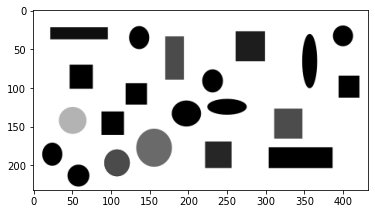

In [131]:
%matplotlib inline
img = Image.open("ejemplo_color.png").convert("I")
plt.imshow(img)

In [132]:
lista = countCCImageBB(img,show=False)
tipos = { 'circulo':[], 'elipse':[], 'cuadrado':[], 'rectangulo':[]}
for npix,bbox in lista:
    tipo = clasificaFigura(npix,bbox)
    tipos[tipo].append(bbox.center())

for tipo in ['circulo','elipse','cuadrado','rectangulo']:
    cuantos = len(tipos[tipo])
    plural = 's' if cuantos!=1 else ''
    oa = 'a' if tipo=='elipse' else 'o'
    print(f'Hay {cuantos} {tipo+plural} centrad{oa+plural} en:')
    for c in tipos[tipo]:
        print(" -",c)

Hay 7 circulos centrados en:
 - (400.5, 33.0)
 - (136.5, 35.0)
 - (231.5, 91.0)
 - (197.5, 133.0)
 - (24.5, 185.5)
 - (108.0, 196.5)
 - (58.5, 212.5)
Hay 2 elipses centradas en:
 - (357.0, 65.5)
 - (250.0, 124.5)
Hay 7 cuadrados centrados en:
 - (280.5, 46.5)
 - (61.5, 85.5)
 - (408.0, 98.5)
 - (133.0, 107.5)
 - (329.5, 145.5)
 - (103.0, 145.5)
 - (239.0, 186.5)
Hay 3 rectangulos centrados en:
 - (59.0, 29.5)
 - (182.5, 61.0)
 - (345.5, 190.0)
